# Telco Customer Churn Prediction Using Machine Learning

This project develops and evaluates supervised machine learning models to predict whether a telecommunications customer is likely to discontinue the service. The work covers the complete workflow from understanding the business problem and preparing the data to model comparison, saving the selected model and demonstrating predictions through a Gradio interface.

# 1. Business Understanding and Problem Statement

Customer churn occurs when a customer stops using a company's services. In the telecommunications industry, understanding the factors associated with churn can help a business identify customers who may be at risk of leaving.

**Project objective:** I developed a binary classification solution that uses customer demographic, account, service and billing information to predict whether a customer will churn (`Yes`) or stay (`No`).

**Target variable:** `Churn`, where `1` represents a customer who churns and `0` represents a customer who stays.

**Project approach:** I prepared the dataset, explored customer characteristics, built preprocessing pipelines, trained four classification algorithms, compared their test performance and selected a model for an interactive demonstration.

### Problem Statement

Customer churn represents the percentage of customers that stop subscribing to a company's services. In the telecommunications sector, acquiring new clients is significantly more costly than retaining existing ones. Predicting customer churn allows organizations to proactively identify subscribers at high risk of cancellation and offer targeted retention incentives.

### Objective

To build, evaluate, and compare multiple machine learning classification models that predict customer churn based on account information, demographics, and subscribed services.

### Machine Learning Type

Supervised Learning — Binary Classification

### Target Variable

`Churn` (Yes / No)

### Algorithms Tested

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. K-Nearest Neighbors (KNN)

### Evaluation Metrics

* Accuracy Score
* ROC-AUC Score
* Precision, Recall, and F1-Score (Classification Report)

### Deployment

Save the trained pipeline model and column artifacts using Python's `pickle` library, and deploy the best-performing model interactively using **Gradio**.

# 2. Import Libraries

I imported the core libraries required for data handling and numerical operations. Additional libraries are imported in the sections where they are used.

In [1]:
import numpy as np
import pandas as pd

# 3. Dataset Loading

I loaded the Telco Customer Churn dataset into a Pandas DataFrame. Each row represents one customer, and the columns contain the customer's demographic, account, subscribed-service and billing information.

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 3.1 Dataset Loading — Observation

The dataset contains **7,043 customer records and 21 columns**. Each record represents one customer. The `Churn` column is the prediction target, while the remaining columns describe customer characteristics and services.

# 4. Data Understanding

I examined the dataset structure, column names, data types and descriptive statistics before preparing the data for modelling. This step establishes which variables are numerical, which are categorical and how the values are distributed.

In [5]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [6]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [7]:
print("\nStatistical Summary:")
display(df.describe())


Statistical Summary:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### 4.1 Statistical Summary — Interpretation

The descriptive summary provides an initial view of the numerical variables, including their central values and spread. At this point, `TotalCharges` is still stored as text, so it is not included in the numerical summary until it is converted during data cleaning.

# 5. Data Cleaning and Quality Check

I checked the dataset for missing values and duplicate records. I also converted `TotalCharges` to a numeric data type so that blank or whitespace-only entries could be identified as missing values and handled consistently during preprocessing.

In [8]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [9]:
# Clean 'TotalCharges' column (convert whitespace strings like ' ' to NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [10]:
print("\nMissing values after cleaning TotalCharges:")
print(df.isnull().sum())


Missing values after cleaning TotalCharges:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


### 5.1 Missing-Value Analysis — Observation

The initial null check does not identify whitespace-only entries in `TotalCharges` because the column is stored as text. After numeric conversion, these entries become missing values. The preprocessing pipeline later handles numerical missing values using median imputation.

In [11]:
print("\nDuplicate rows:")
print(df.duplicated().sum())


Duplicate rows:
0


### 5.2 Duplicate-Record Check — Observation

The duplicate check reports **0 complete duplicate rows**. Therefore, no exact duplicate records were detected across all columns in this dataset.

# 6. Exploratory Data Analysis (EDA)

I used visual analysis to understand the target distribution, inspect numerical variables and examine relationships among numerical features. These observations provide context for the modelling decisions.

### 6.2 Numerical Feature Outlier Inspection

I inspected the numerical features `tenure`, `MonthlyCharges` and `TotalCharges` using boxplots. This helps identify unusually low or high observations and understand the spread of the customer data. The inspection is descriptive; the project does not remove these observations.


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

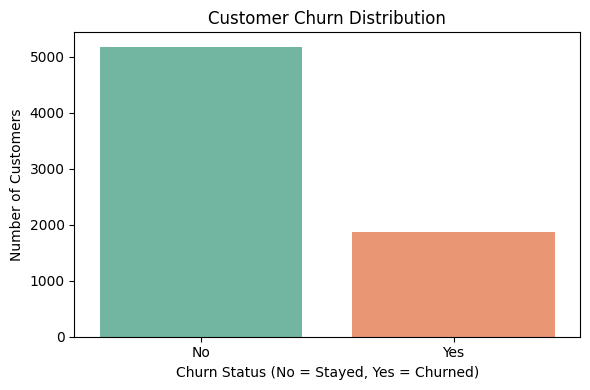

In [13]:
# Customer Churn Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df, hue='Churn', palette='Set2', legend=False)
plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status (No = Stayed, Yes = Churned)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


### 6.1 Churn Distribution — Interpretation

The chart shows the relative frequency of the two target classes, `No` and `Yes`. The larger class represents the more common customer outcome in this dataset. This distribution is important when interpreting model accuracy, so I use a stratified train-test split and also compare ROC-AUC.

Text(0.5, 1.0, 'Tenure Outlier Check')

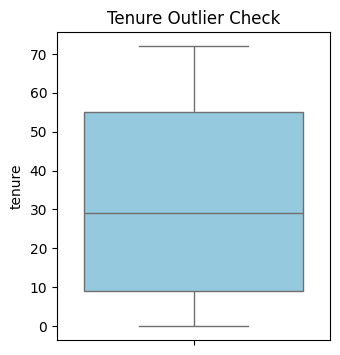

In [14]:
# Outlier Detection (Boxplots for Numerical Features)
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.boxplot(y=df['tenure'], color='skyblue')
plt.title("Tenure Outlier Check")

Text(0.5, 1.0, 'Monthly Charges Outlier Check')

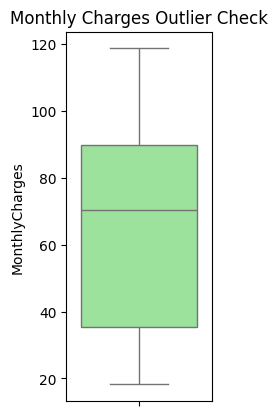

In [15]:
plt.subplot(1, 3, 2)
sns.boxplot(y=df['MonthlyCharges'], color='lightgreen')
plt.title("Monthly Charges Outlier Check")

Text(0.5, 1.0, 'Total Charges Outlier Check')

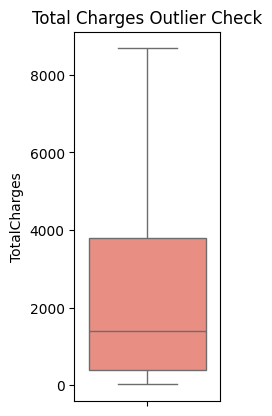

In [16]:
plt.subplot(1, 3, 3)
sns.boxplot(y=df['TotalCharges'], color='salmon')
plt.title("Total Charges Outlier Check")

### 6.2 Boxplot Analysis — Interpretation

The boxplots summarize the spread of each numerical feature and highlight observations beyond the whiskers. Such points are potential outliers, but they may represent genuine customer records. I retain the observations and allow the classification models to learn from the available data.

### 6.3 Numerical Feature Distributions

I plotted histograms for `tenure`, `MonthlyCharges` and `TotalCharges` to examine their distributions, concentration of values and spread.

Text(0.5, 1.0, 'Tenure Distribution')

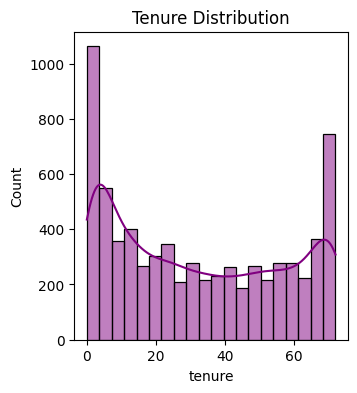

In [17]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.histplot(df['tenure'], kde=True, color='purple', bins=20)
plt.title('Tenure Distribution')

Text(0.5, 1.0, 'Monthly Charges Distribution')

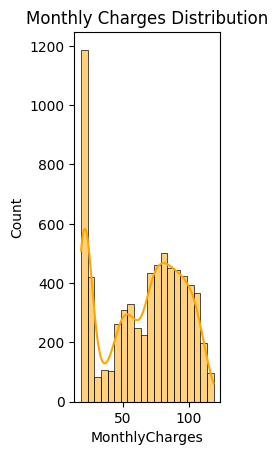

In [18]:
plt.subplot(1, 3, 2)
sns.histplot(df['MonthlyCharges'], kde=True, color='orange', bins=20)
plt.title('Monthly Charges Distribution')

Text(0.5, 1.0, 'Total Charges Distribution')

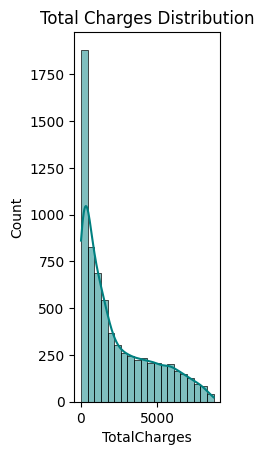

In [19]:
plt.subplot(1, 3, 3)
sns.histplot(df['TotalCharges'], kde=True, color='teal', bins=20)
plt.title('Total Charges Distribution')

### 6.3 Distribution Analysis — Interpretation

The histograms show how customer tenure and charges are distributed across the dataset. These patterns provide context about customer account duration and billing amounts. The numerical features are standardized within the preprocessing pipeline before model training.

### 6.4 Correlation Analysis of Numerical Features

I used a correlation heatmap to inspect pairwise linear relationships among the numerical columns. This provides an overview of how numerical customer attributes vary together.

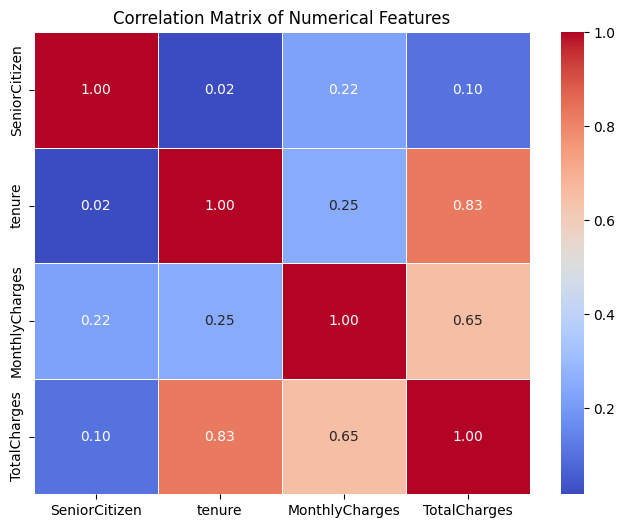

In [20]:
# Feature Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=['int64', 'float64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Numerical Features")
plt.show()

### 6.4 Correlation Heatmap — Interpretation

The heatmap displays Pearson correlation coefficients for the numerical columns. Values nearer to `+1` indicate a stronger positive linear relationship, values nearer to `-1` indicate a stronger negative relationship, and values near `0` indicate a weaker linear relationship. Correlation describes association and does not establish causation.

# 7. Feature and Target Preparation

I removed the customer identifier because it is used to distinguish individual records rather than describe customer behaviour. I then encoded the target variable and separated the predictor matrix (`X`) from the target (`y`).

In [21]:
# Drop unique identifier column with no predictive power
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

### 7.1 Customer Identifier Removal — Rationale

`customerID` is excluded because it is an identifier rather than a meaningful service, demographic or billing feature. Removing it leaves the customer attributes that are used as predictors.

In [22]:
# Encode target variable to binary (1 for Yes, 0 for No)
df['Churn'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

In [23]:
X = df.drop(columns=['Churn'])
y = df['Churn']

In [24]:
print("Features shape:", X.shape)

Features shape: (7043, 19)


In [25]:
print("Target shape:", y.shape)

Target shape: (7043,)


### 7.2 Input and Target Separation — Observation

`X` contains the **19 predictor features**, and `y` contains the binary `Churn` target. The target encoding is **1 = Yes (churn)** and **0 = No (stay)**.

### 7.3 Train-Test Split

I divided the prepared predictor data and target labels into training and testing subsets using an 80:20 split. The training subset is used to fit the preprocessing steps and classification models, while the test subset is held out for final performance evaluation.

In [26]:
# Split data into Train (80%) and Test (20%) sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [27]:
print("\nTraining records:", X_train.shape[0])


Training records: 5634


In [28]:
print("Testing records:", X_test.shape[0])

Testing records: 1409


### 7.3 Train-Test Split — Interpretation

The split creates **5,634 training records (80%)** and **1,409 testing records (20%)**. I used `stratify=y` to preserve approximately the same churn/non-churn class proportions in both subsets. `random_state=42` makes the split reproducible.

# 8. Data Preprocessing Pipeline

The dataset contains numerical and categorical predictors, which require different transformations. I created a `ColumnTransformer` containing separate pipelines and integrated this preprocessing object into each classifier. This ensures that transformations are fitted on the training data and then consistently applied to test records and new customer inputs.

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

### 8.1 Identify Numerical and Categorical Features

I separated the 19 predictor columns according to their data types. Numerical columns are processed with imputation and scaling, while categorical columns are processed with imputation and one-hot encoding.

In [30]:
categorical_features = X.select_dtypes(include=['object']).columns

numerical_features = X.select_dtypes(include=['number']).columns

print("Numerical Features:")
print(list(numerical_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### 8.1 Feature-Type Identification — Output Insight

The output identifies **4 numerical features** and **15 categorical features**, accounting for all 19 predictors. This separation determines which preprocessing operations are applied to each column group.

### 8.2 Numerical Feature Pipeline

For numerical features, I used median imputation to fill missing values and `StandardScaler` to standardize the feature values. Standardization is particularly relevant for algorithms such as Logistic Regression and KNN, which can be affected by differences in feature scale.

In [31]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

### 8.3 Categorical Feature Pipeline

For categorical features, I used most-frequent-value imputation followed by One-Hot Encoding. `drop='first'` removes one category from each encoded feature to reduce redundant indicator columns, while `handle_unknown='ignore'` allows the pipeline to process categories not encountered during fitting.

In [32]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

### 8.4 Combine the Preprocessing Pipelines

I combined the numerical and categorical transformations using `ColumnTransformer`. The resulting preprocessing object is included in every model pipeline, so each model receives the same transformed feature representation.

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


### 8.4 Combined Preprocessor — Output Insight

The preprocessing object has been assembled successfully. It will be fitted separately within each model pipeline using the training data, preventing test-set information from being used to learn imputation values, scaling parameters or encoding categories.

### 8.5 Preprocessing Pipeline — Outcome

The preprocessing pipeline is created successfully. It handles the numerical columns (`SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges`) separately from the categorical customer and service columns. Because it is part of each model pipeline, preprocessing is fitted using the training subset rather than the complete dataset.

# 9. Model Building and Training

I implemented four supervised binary classification algorithms to compare different approaches to customer churn prediction. Each algorithm is wrapped in the same preprocessing pipeline and trained using the same training subset. This makes the comparison consistent because the models receive the same input features and preprocessing operations.

**Predictor features used by every model:** all 19 independent variables, covering customer demographics, account information, phone services, internet services and billing details. No separate feature-selection algorithm is applied; the identifier is removed and the remaining predictors are used.

### 9.0 Predictor Features Used by All Models

I used the same **19 independent features** for each algorithm. They describe several aspects of a customer's relationship with the telecommunications provider:

| Feature group | Features |
|---|---|
| Demographic | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Account | `tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod` |
| Phone services | `PhoneService`, `MultipleLines` |
| Internet services | `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Billing | `MonthlyCharges`, `TotalCharges` |

These features were retained because they represent customer profile, account duration, subscribed services and billing behaviour. Each model receives these same predictors after the shared preprocessing pipeline.

### 9.1 Logistic Regression

**What the algorithm is:** Logistic Regression is a supervised classification algorithm that estimates the probability of an observation belonging to a class. In this project, it estimates the probability that a customer will churn.

**How it works:** The algorithm learns a coefficient for each transformed predictor and combines these values into a score. The logistic (sigmoid) function converts the score into a probability between 0 and 1. The classifier then assigns a class using its decision threshold.

**Why I used it:** It is a suitable baseline for binary classification, produces probability estimates and provides a relatively interpretable model for comparing customer attributes with churn outcomes.

**Features used:** All 19 predictor features are supplied through the shared preprocessing pipeline. These include tenure, charges, contract type, internet and phone services, payment method and customer demographic information.

**Configuration:** `max_iter=1000` sets the maximum number of solver iterations, and `random_state=42` makes the solver's randomized behaviour reproducible where applicable.

In [34]:
from sklearn.linear_model import LogisticRegression

# 1. Logistic Regression Pipeline
log_reg = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]
)

# Train the model
log_reg.fit(X_train, y_train)

print("Logistic Regression training completed successfully!")

Logistic Regression training completed successfully!


### 9.1.1 Logistic Regression — Training Outcome

The Logistic Regression pipeline was fitted using **5,634 training records**. During fitting, the pipeline learned the numerical imputation and scaling parameters, categorical imputation and encoding categories, and the classifier coefficients. The fitted pipeline is ready to predict churn for the held-out test records.

### 9.2 Decision Tree Classifier

**What the algorithm is:** A Decision Tree is a supervised learning algorithm that predicts a class by applying a sequence of feature-based decision rules. Its structure contains a root node, decision nodes, branches and leaf nodes.

**How it works:** The algorithm repeatedly selects splits that separate the training observations into more homogeneous groups with respect to the churn target. A new customer record follows the learned rules until it reaches a leaf containing the predicted class.

**Why I used it:** A Decision Tree can represent non-linear relationships and interactions between customer characteristics. It also provides a rule-based structure that is easier to inspect than many more complex models.

**Features used:** The model uses the same 19 predictor features and shared preprocessing pipeline as the other classifiers.

**Configuration:** `random_state=42` makes the randomized parts of tree construction reproducible. Other tree parameters use the Scikit-learn defaults; no explicit depth limit or hyperparameter search is applied.

In [35]:
from sklearn.tree import DecisionTreeClassifier

# 2. Decision Tree Pipeline
dt_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeClassifier(random_state=42))
    ]
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree training completed successfully!")

Decision Tree training completed successfully!


### 9.2.1 Decision Tree — Training Outcome

The Decision Tree pipeline was fitted using **5,634 training records**. The tree learned feature-based splitting rules from the preprocessed customer records. Its performance is assessed on the same held-out test set used for the other three classifiers.

### 9.3 Random Forest Classifier

**What the algorithm is:** Random Forest is an ensemble classification algorithm that combines predictions from multiple decision trees.

**How it works:** Each tree is trained using a bootstrap sample of the training data and considers randomized feature subsets when selecting splits. For classification, the trees' predictions are combined through majority voting.

**Why I used it:** Combining trees can reduce the variance associated with relying on one decision tree and can capture non-linear relationships among customer attributes.

**Features used:** The model uses the same 19 predictor features and shared preprocessing pipeline as the other classifiers.

**Configuration:** `n_estimators=100` creates 100 decision trees. `random_state=42` supports reproducibility of the model's randomized operations. Other parameters use the Scikit-learn defaults.

In [36]:
from sklearn.ensemble import RandomForestClassifier

# 3. Random Forest Pipeline
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestClassifier(n_estimators=100, random_state=42))
    ]
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")

Random Forest training completed successfully!


### 9.3.1 Random Forest — Training Outcome

The Random Forest pipeline was fitted using **5,634 training records** and configured with **100 decision trees**. The ensemble combines the individual tree predictions to produce a final churn classification. Its performance is compared with the other models on the same test records.

### 9.4 K-Nearest Neighbors (KNN)

**What the algorithm is:** K-Nearest Neighbors is a supervised, instance-based classification algorithm. It predicts the class of a new observation by examining the labels of nearby training observations.

**How it works:** KNN calculates distances between a new customer record and the training records, selects the nearest `K` observations and assigns the majority class among those neighbors.

**Why I used it:** KNN provides a distance-based approach that can identify local patterns in customer data and offers a useful contrast to the coefficient-based and tree-based algorithms.

**Features used:** KNN uses the same 19 predictor features after the shared preprocessing pipeline.

**Why scaling matters:** Distance calculations can be dominated by variables with larger numeric ranges. `StandardScaler` places numerical features on comparable scales before KNN calculates distances.

**Configuration:** `n_neighbors=5` means that the five nearest training observations are considered for each prediction. Other parameters use the Scikit-learn defaults.

In [37]:
from sklearn.neighbors import KNeighborsClassifier

# 4. K-Nearest Neighbors Pipeline
knn_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]
)

# Train the model
knn_model.fit(X_train, y_train)

print("K-Nearest Neighbors training completed successfully!")

K-Nearest Neighbors training completed successfully!


### 9.4.1 KNN — Training Outcome

The KNN pipeline was fitted using **5,634 training records**. The preprocessing stage standardizes numerical features before the classifier uses distance calculations. At prediction time, the model considers the five nearest training observations and assigns the majority class.

# 10. Model Evaluation and Comparison

I evaluated each fitted pipeline using the same **1,409 held-out test records**. I used Accuracy to measure the proportion of correct class predictions and ROC-AUC to measure how well the model ranks churn cases above non-churn cases across classification thresholds.

In [38]:
from sklearn.metrics import accuracy_score, roc_auc_score

In [39]:
models = {
    "Logistic Regression": log_reg,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "KNN": knn_model
}

In [40]:
results = []

for model_name, model in models.items():

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)

    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "ROC-AUC": roc_auc
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.805536,0.842008
1,Decision Tree,0.740951,0.660957
2,Random Forest,0.785664,0.824450
3,KNN,0.766501,0.792593


### 10.1 Model Comparison — Result Insight

The executed results show that Logistic Regression has the highest accuracy (**0.8055**) and ROC-AUC (**0.8420**) in this comparison. Random Forest is the next strongest model by ROC-AUC (**0.8245**), followed by KNN (**0.7926**) and Decision Tree (**0.6610**).

### 10.1 Evaluation Results — Interpretation

The results table reports each model's performance on the unseen test subset. Accuracy summarizes overall classification correctness, while ROC-AUC measures the model's ability to distinguish churners from customers who stay across different decision thresholds. I use ROC-AUC as the primary criterion for selecting the final model.

### 10.2 Accuracy Comparison

The chart below compares the accuracy scores of the four classifiers on the same test dataset.

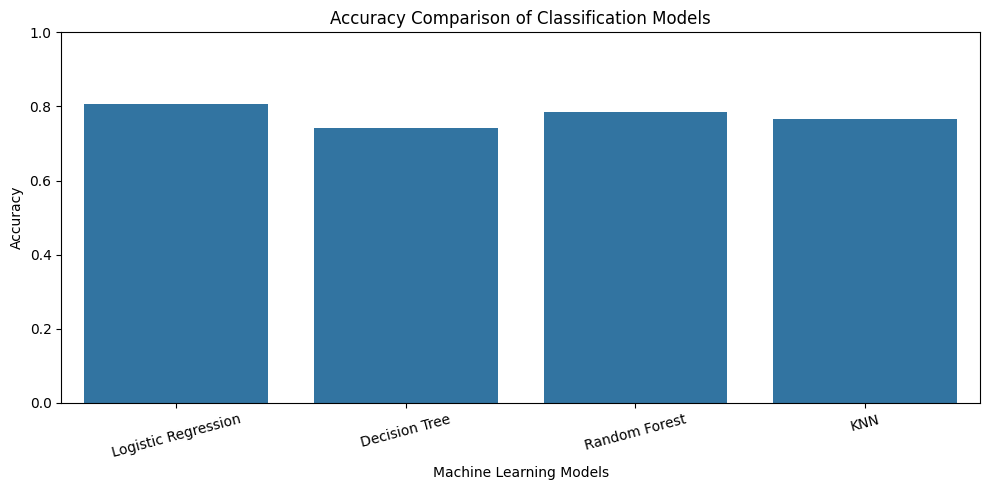

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 10.3 ROC-AUC Comparison

The chart below compares the ROC-AUC scores, which indicate how effectively each classifier distinguishes between churn and non-churn customers across thresholds.

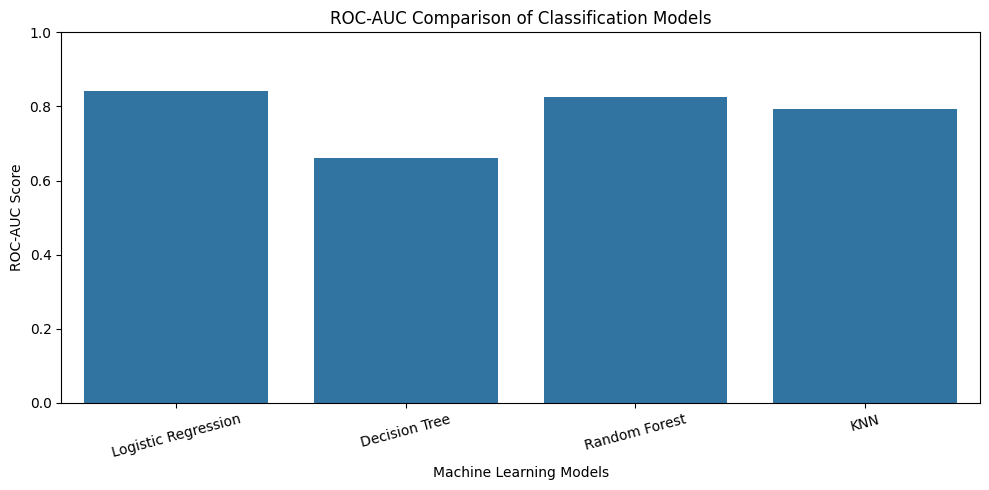

In [42]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC-AUC"
)

plt.title("ROC-AUC Comparison of Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("ROC-AUC Score")
plt.ylim(0, 1)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 10.4 Model Performance — Graphical Analysis

The two charts provide complementary views of model performance. Accuracy compares the proportion of correct predictions at the models' default classification thresholds, while ROC-AUC compares their ranking ability across thresholds. Logistic Regression records the strongest result on both measures in this experiment.

# 11. Best Model Selection

I selected the final classifier using ROC-AUC as the primary metric. This metric is useful for comparing binary classifiers because it evaluates ranking performance across thresholds rather than relying on one fixed classification threshold.

### 11.1 Select the Best Model

The following code sorts the evaluation results by ROC-AUC in descending order and selects the model with the highest score.

In [43]:
best_model_name = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Logistic Regression


### 11.2 Selected Model — Performance

The selected model's accuracy and ROC-AUC are displayed below to summarize its performance on the held-out test data.

In [44]:
best_result = results_df[
    results_df["Model"] == best_model_name
]

print("Selected Model:", best_model_name)
print("Accuracy:", round(best_result["Accuracy"].iloc[0], 4))
print("ROC-AUC:", round(best_result["ROC-AUC"].iloc[0], 4))

Selected Model: Logistic Regression
Accuracy: 0.8055
ROC-AUC: 0.842


### 11.3 Best Model — Selection Outcome

Logistic Regression achieved the highest ROC-AUC (**0.8420**) and the highest accuracy (**0.8055**) among the four evaluated models. I therefore selected Logistic Regression as the final model for saving and use in the Gradio demonstration.

# 12. Model Saving and Loading

After selecting Logistic Regression, I saved the complete fitted pipeline using Python's `pickle` module. Saving the pipeline preserves both the preprocessing transformations and the trained classifier, allowing the same transformations to be reused when making predictions.

In [45]:
import pickle

### 12.1 Save the Trained Pipeline

I saved the selected fitted pipeline as `churn_model.pkl`. The saved object contains the preprocessing steps and the Logistic Regression classifier.

In [46]:
with open("churn_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Best Model Saved Successfully!")

Best Model Saved Successfully!


### 12.2 Save the Input Feature Names

I also saved the original predictor column names as `model_columns.pkl`. These names are used to arrange incoming customer details in the same column order expected by the trained pipeline.

In [47]:
model_columns = X.columns.tolist()

with open("model_columns.pkl", "wb") as file:
    pickle.dump(model_columns, file)

print("Model Columns Saved Successfully!")

Model Columns Saved Successfully!


### 12.3 Model Saving — Outcome

The fitted model pipeline and its expected input feature names have been saved as separate pickle files. The pipeline can be loaded later without repeating model training.

# 13. Model Deployment Using Gradio

I created an interactive Gradio interface to demonstrate the selected model. The interface accepts the same 19 customer attributes used during training and displays the predicted churn class together with the model-estimated churn probability. This is an interactive demonstration, not a claim of permanent production hosting.

In [48]:
import gradio as gr
import pandas as pd
import pickle

### 13.1 Load the Saved Model

I loaded the saved pipeline and feature-column list from their pickle files. Loading the fitted pipeline makes the same preprocessing and prediction steps available to the application.

In [49]:
with open("churn_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

with open("model_columns.pkl", "rb") as file:
    model_columns = pickle.load(file)

print("Model Loaded Successfully!")

Model Loaded Successfully!


### 13.2 Prediction Function

The prediction function collects the values entered in the interface, constructs a one-row DataFrame, orders the columns using the saved feature list and passes the record to the loaded pipeline. It returns the predicted class and the model-estimated probability of churn.

In [50]:
def predict_churn(
    gender,
    SeniorCitizen,
    Partner,
    Dependents,
    tenure,
    PhoneService,
    MultipleLines,
    InternetService,
    OnlineSecurity,
    OnlineBackup,
    DeviceProtection,
    TechSupport,
    StreamingTV,
    StreamingMovies,
    Contract,
    PaperlessBilling,
    PaymentMethod,
    MonthlyCharges,
    TotalCharges
):

    customer_data = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": SeniorCitizen,
        "Partner": Partner,
        "Dependents": Dependents,
        "tenure": tenure,
        "PhoneService": PhoneService,
        "MultipleLines": MultipleLines,
        "InternetService": InternetService,
        "OnlineSecurity": OnlineSecurity,
        "OnlineBackup": OnlineBackup,
        "DeviceProtection": DeviceProtection,
        "TechSupport": TechSupport,
        "StreamingTV": StreamingTV,
        "StreamingMovies": StreamingMovies,
        "Contract": Contract,
        "PaperlessBilling": PaperlessBilling,
        "PaymentMethod": PaymentMethod,
        "MonthlyCharges": MonthlyCharges,
        "TotalCharges": TotalCharges
    }])

    customer_data = customer_data[model_columns]

    prediction = loaded_model.predict(customer_data)[0]

    probability = loaded_model.predict_proba(customer_data)[0][1]

    if prediction == 1:
        result = "Customer is likely to Churn"
    else:
        result = "Customer is likely to Stay"

    return result, f"{probability * 100:.2f}%"

### 13.3 Gradio Interface

I defined the input controls to match the dataset's feature categories and numeric fields. The interface calls `predict_churn` and displays two outputs: the predicted churn status and the model-estimated churn probability.

In [51]:
demo = gr.Interface(
    fn=predict_churn,

    inputs=[
        gr.Radio(["Male", "Female"], label="Gender"),
        gr.Radio([0, 1], label="Senior Citizen"),
        gr.Radio(["Yes", "No"], label="Partner"),
        gr.Radio(["Yes", "No"], label="Dependents"),
        gr.Number(label="Tenure (Months)"),
        gr.Radio(["Yes", "No"], label="Phone Service"),
        gr.Dropdown(
            ["Yes", "No", "No phone service"],
            label="Multiple Lines"
        ),
        gr.Dropdown(
            ["DSL", "Fiber optic", "No"],
            label="Internet Service"
        ),
        gr.Dropdown(
            ["Yes", "No", "No internet service"],
            label="Online Security"
        ),
        gr.Dropdown(
            ["Yes", "No", "No internet service"],
            label="Online Backup"
        ),
        gr.Dropdown(
            ["Yes", "No", "No internet service"],
            label="Device Protection"
        ),
        gr.Dropdown(
            ["Yes", "No", "No internet service"],
            label="Tech Support"
        ),
        gr.Dropdown(
            ["Yes", "No", "No internet service"],
            label="Streaming TV"
        ),
        gr.Dropdown(
            ["Yes", "No", "No internet service"],
            label="Streaming Movies"
        ),
        gr.Dropdown(
            ["Month-to-month", "One year", "Two year"],
            label="Contract"
        ),
        gr.Radio(["Yes", "No"], label="Paperless Billing"),
        gr.Dropdown(
            [
                "Electronic check",
                "Mailed check",
                "Bank transfer (automatic)",
                "Credit card (automatic)"
            ],
            label="Payment Method"
        ),
        gr.Number(label="Monthly Charges"),
        gr.Number(label="Total Charges")
    ],

    outputs=[
        gr.Textbox(label="Churn Prediction"),
        gr.Textbox(label="Churn Probability")
    ],

    title="Telco Customer Churn Prediction",
    description="Enter customer details to predict the likelihood of customer churn."
)

demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://5f3fedd2f554eafd96.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Created dataset file at: .gradio\flagged\dataset1.csv


### 13.4 Deployment — Outcome

The Gradio interface provides an interactive way to submit customer details and obtain a churn prediction. The output includes the predicted status (`likely to Churn` or `likely to Stay`) and a model-estimated churn probability. The share URL generated by `demo.launch(share=True)` is temporary and should be treated as a demonstration link.

# 14. Final Project Insights and Conclusion

This project implements an end-to-end supervised machine learning workflow for telecommunications customer churn prediction. The workflow includes data understanding, cleaning, exploratory analysis, feature and target preparation, preprocessing, model training, evaluation, model selection, saving and an interactive Gradio demonstration.

### 14.1 Key Project Findings

- The dataset contains **7,043 customer records and 21 original columns**.
- After removing `customerID` and separating `Churn`, the model uses **19 predictor features**.
- Converting `TotalCharges` to numeric exposed **11 missing values**, which are handled by the numerical imputation pipeline.
- The data was divided into **5,634 training records** and **1,409 testing records**, using stratification.
- Numerical and categorical variables are handled through separate preprocessing pipelines.
- Four classification algorithms were trained and evaluated using the same test dataset.

### 14.2 Model Performance Summary

The following values are taken from the executed model evaluation output. Accuracy and ROC-AUC are shown to three decimal places.

| Model | Accuracy | ROC-AUC |
|---|---:|---:|
| Logistic Regression | 0.806 | 0.842 |
| Decision Tree | 0.741 | 0.661 |
| Random Forest | 0.786 | 0.824 |
| K-Nearest Neighbors | 0.767 | 0.793 |

Logistic Regression achieved the highest accuracy and ROC-AUC among the four models in this experiment.

### 14.3 Project Outcome

The project produced four trained classification pipelines and selected Logistic Regression as the best-performing model according to ROC-AUC. The selected pipeline achieved **80.6% accuracy** and a **0.842 ROC-AUC** on the held-out test dataset. The fitted pipeline and expected feature names were saved, and a Gradio interface was created to demonstrate predictions for customer-entered information.

### 14.4 Conclusion

I developed a machine learning solution to predict customer churn using demographic, account, service and billing information. I compared Logistic Regression, Decision Tree, Random Forest and K-Nearest Neighbors under a consistent preprocessing and evaluation workflow. Logistic Regression produced the strongest results on the selected test metrics and was therefore saved for the interactive demonstration. The project shows how customer data can be used to identify patterns associated with churn and provide a model-based indication of churn risk.